# DS2002 · Midterm Checkpoint

**Lab — 2026-10-23 · Fall 2026**  

---

## Lab 09 — Midterm checkpoint, week 1 of 3

**What you submit: the link to your team's main repo. Only that.** One submission per team. Do not upload separate files.

Put this notebook in the repo (the `notebooks/` folder is fine) and push it, so everything we check is in one place.

**You do not have to fill this all out.** It is a checkpoint, not a finished project. Skip any section you have not started and write "not started" next to it. What we must see is:

1. **Your charter**, committed to the repo
2. **Any progress** you have made, with code that ran and output you can point at

Start with the team setup, then work down the same eight things we listed at Monday's kickoff, as far as you have gotten. This is graded on evidence, not on intentions.

The purpose is to catch a stalled team while there is still time to unstall it. If something is not working, say so here plainly. A checkpoint that honestly reports "the API join is not working and here is the error" is worth more than one that claims progress that does not exist, and it gets you help on Monday.

### Team setup

This part is required. Fill it in once for the whole team.

You need:

- Your team name, and every member with a GitHub handle (2 to 4 people)
- A link to your team's **main repo**. This is the one link you submit.
- A link to `CHARTER.md` in that repo, the page on GitHub, not a file on someone's laptop

Nice to have, and also in your charter: this week's notebook owner, your meeting time, and the five worst problems in the data from the profile you ran on Monday. Be specific: "`unit_price` is stored as text and some values start with `$`" beats "prices are messy."

In [3]:
team_setup = {
    'team_name': 'Ramen',
    'members': [                                  # everyone on the team, 2 to 4 people
        {'name': 'Antony Lin', 'github': 'antonylin0428'},
        {'name': 'Danny', 'github': 'zhang-dny'},
    ],
    'repo_url': 'https://github.com/zhang-dny/walmart-hurricane-project',                           # your main team repo: https://github.com/...
    'charter_url': 'https://github.com/zhang-dny/walmart-hurricane-project/blob/main/CHARTER.md',                        # link to CHARTER.md in that repo
    'notebook_owner_this_week': 'Antony',           # nice to have
    'meeting_time': 'Tue and Thu 5pm',                       # nice to have, e.g. 'Tue and Thu 7pm'
    'five_worst_problems': ['TODO'],              # nice to have, five specific problems
}

def check_team(t, quiet=False):
    def real(v):
        return isinstance(v, str) and v.strip() != '' and not v.startswith('TODO')
    required = {
        'team name': real(t['team_name']),
        '2 to 4 members, each with a name and GitHub handle':
            2 <= len(t['members']) <= 4 and all(real(m['name']) and real(m['github']) for m in t['members']),
        'main repo link': real(t['repo_url']) and t['repo_url'].startswith('https://github.com/'),
        'charter link points at CHARTER.md': real(t['charter_url']) and t['charter_url'].endswith('CHARTER.md'),
    }
    nice = {
        'notebook owner': real(t['notebook_owner_this_week']),
        'meeting time': real(t['meeting_time']),
        'five specific problems': len(t['five_worst_problems']) >= 5 and all(real(p) for p in t['five_worst_problems']),
    }
    if not quiet:
        print('REQUIRED')
        for label, good in required.items():
            print('  PASS' if good else '  FAIL', '-', label)
        print('NICE TO HAVE')
        for label, good in nice.items():
            print('  done' if good else '  not yet', '-', label)
        print()
        print('team setup complete:', all(required.values()))
    return all(required.values())

check_team(team_setup)

REQUIRED
  PASS - team name
  PASS - 2 to 4 members, each with a name and GitHub handle
  PASS - main repo link
  PASS - charter link points at CHARTER.md
NICE TO HAVE
  done - notebook owner
  done - meeting time
  not yet - five specific problems

team setup complete: True


True

Now show that the charter is actually committed. This is required. Run the next cell and leave its output in the notebook. Point `REPO_PATH` at your local clone of the team repo. If it prints a line like `a1b2c3d Add team charter`, you are done. If it prints "no commits found," the charter is not in the repo yet, so commit it and push before you submit.

In [8]:
import subprocess
from pathlib import Path

REPO_PATH = Path("/content/walmart-hurricane-project")

if not REPO_PATH.exists():
    subprocess.run([
        "git", "clone",
        "https://github.com/zhang-dny/walmart-hurricane-project.git",
        str(REPO_PATH)
    ], check=True)

result = subprocess.run(
    ["git", "-C", str(REPO_PATH),
     "log", "--oneline", "--", "CHARTER.md"],
    capture_output=True,
    text=True
)

print(result.stdout.strip() or result.stderr.strip()
      or "no commits found for CHARTER.md")

2eb8985 updated charter.md and readme
110c665 initial project commit


### 1 — Your cleaning pipeline as functions

**TODO:** paste the cleaning code you have written so far. It should be functions, not loose cells, and it should cover at minimum: duplicates, `unit_price` to numeric (it comes in as text, some with a `$`), the negative `quantity` values with your decision applied, `timestamp` parsed, and `store_id` cleaned up so it will join to the store file.

Print the row count before and after. We want to see how many rows your decisions removed.

In [10]:
# TODO


import pandas as pd


DATA = REPO_PATH / "data"


tx = pd.read_csv(DATA / "walmart_transactions.csv")
stores = pd.read_csv(DATA / "store_locations.csv")


def normalize_store_id(values):
    codes = (
        values.astype("string")
        .str.upper()
        .str.extract(r"(\d{3})", expand=False)
    )
    return "FL-" + codes


def clean_transactions(raw):
    df = raw.copy()
    changes = []


    duplicates = int(df.duplicated().sum())
    df = df.drop_duplicates().copy()

    changes.append({
        "decision": "Removed exact duplicate rows",
        "rows_affected": duplicates
    })


    prices = df["unit_price"].astype("string")

    prices_with_dollar = int(
        prices.str.contains("$", regex=False, na=False).sum()
    )

    df["unit_price"] = pd.to_numeric(
        prices.str.replace("$", "", regex=False)
              .str.replace(",", "", regex=False)
              .str.strip(),
        errors="coerce"
    )

    changes.append({
        "decision": "Removed $ and converted prices to numeric",
        "rows_affected": prices_with_dollar
    })


    df["quantity"] = pd.to_numeric(
        df["quantity"], errors="coerce"
    )

    negative_qty = int((df["quantity"] < 0).sum())
    df["is_return"] = df["quantity"] < 0

    changes.append({
        "decision": "Kept negative quantities as potential returns",
        "rows_affected": negative_qty
    })


    df["timestamp"] = pd.to_datetime(
        df["timestamp"], format="mixed", errors="coerce"
    )

    invalid_dates = int(df["timestamp"].isna().sum())
    df = df.dropna(subset=["timestamp"]).copy()

    df["date"] = df["timestamp"].dt.normalize()

    changes.append({
        "decision": "Dropped rows with invalid timestamps",
        "rows_affected": invalid_dates
    })

    old_ids = df["store_id"].astype("string")
    df["store_id"] = normalize_store_id(df["store_id"])

    fixed_ids = int(
        (old_ids.fillna("") !=
         df["store_id"].fillna("")).sum()
    )

    changes.append({
        "decision": "Standardized store IDs to FL-###",
        "rows_affected": fixed_ids
    })

    return df, pd.DataFrame(changes)



clean_tx, decision_log = clean_transactions(tx)


stores["store_id"] = normalize_store_id(stores["store_id"])

print("Rows before cleaning:", len(tx))
print("Rows after cleaning:", len(clean_tx))

print(
    "Transaction rows without a matching store:",
    (~clean_tx["store_id"].isin(stores["store_id"])).sum()
)

display(clean_tx.head())



Rows before cleaning: 25562
Rows after cleaning: 24648
Transaction rows without a matching store: 0


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,is_return,date
0,TXN012636,FL-710,2024-09-24 09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15,False,2024-09-24
1,TXN000759,FL-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02,False,2024-09-13
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47,False,2024-09-17
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59,False,2024-09-11
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82,False,2024-09-26


### 2 — Your decision log

**TODO:** every cleaning decision, what it did, and how many rows it touched. If your teammates disagree with one of these, note the disagreement — that is useful information, not a problem to hide.

In [11]:
# TODO: print or display your decision log

print("Cleaning Decision Log")
display(decision_log)

print("Total decisions recorded:", len(decision_log))

Cleaning Decision Log


,decision,rows_affected
0,Removed exact duplicate rows,30
1,Removed $ and converted prices to numeric,3026
2,Kept negative quantities as potential returns,130
3,Dropped rows with invalid timestamps,884
4,Standardized store IDs to FL-###,4195


Total decisions recorded: 5


### 3 — SKU consolidation progress

**TODO:** how many distinct SKUs did you start with, how many canonical products do you have now, and what is your largest consolidated group? Show the mapping for at least one product family. Pop-Tarts is a good one to start with.

You do not need this finished — you need it started and defensible.

In [12]:
# TODO

catalog = pd.read_csv(DATA / "product_catalog.csv")

poptart_map = {
    "PT-12": "Pop-Tarts Strawberry",
    "SKU#459812": "Pop-Tarts Strawberry",
    "POPTART-STRAW": "Pop-Tarts Strawberry",
    "PT_STRAWBERRY": "Pop-Tarts Strawberry"
}


catalog["canonical_product"] = (
    catalog["sku"].replace(poptart_map)
)


original_skus = catalog["sku"].nunique()
partial_groups = catalog["canonical_product"].nunique()

print("Original distinct SKUs:", original_skus)
print("Groups after partial consolidation:", partial_groups)

group_sizes = (
    catalog.groupby("canonical_product")["sku"]
    .nunique()
    .sort_values(ascending=False)
)

print("Largest group:", group_sizes.index[0])
print("SKUs in group:", group_sizes.iloc[0])


display(
    catalog[catalog["sku"].isin(poptart_map)]
    [["sku", "product_name", "package_size",
      "canonical_product"]]
)


Original distinct SKUs: 45
Groups after partial consolidation: 42
Largest group: Pop-Tarts Strawberry
SKUs in group: 4


,sku,product_name,package_size,canonical_product
0,PT-12,pop-tarts strawberry,4-pack,Pop-Tarts Strawberry
1,SKU#459812,Strawberry Pop-Tart,4pk,Pop-Tarts Strawberry
2,POPTART-STRAW,Pop-Tarts Strawberry,6 pack,Pop-Tarts Strawberry
3,PT_STRAWBERRY,pop-tarts strawberry,4 pack,Pop-Tarts Strawberry


### 4 — One working weather API call

**TODO:** show the call and the parsed DataFrame. It must include the retry logic and a `source` column. Say which timezone the weather timestamps are in and how you will line them up with the sales timestamps. If it is not working, paste the actual error and what you have tried.

In [13]:
# TODO

import requests
import time

BASE = "https://archive-api.open-meteo.com/v1/archive"
RETRY_STATUSES = {429, 500, 502, 503, 504}

def daily_weather(start, end, lat=28.54, lon=-81.38, tries=3):
    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": start,
        "end_date": end,
        "daily": "precipitation_sum,wind_speed_10m_max",
        "timezone": "America/New_York"
    }

    for attempt in range(1, tries + 1):
        try:
            response = requests.get(
                BASE, params=params, timeout=10
            )

            response.raise_for_status()

            weather_df = pd.DataFrame(
                response.json()["daily"]
            )

            weather_df = weather_df.rename(
                columns={"time": "date"}
            )

            weather_df["date"] = pd.to_datetime(
                weather_df["date"]
            )

            weather_df["source"] = "open-meteo"

            return weather_df

        except requests.RequestException as error:
            if attempt == tries or (
                isinstance(error, requests.HTTPError)
                and response.status_code not in RETRY_STATUSES
            ):
                raise

            time.sleep(2 ** attempt)



weather = pd.DataFrame()

try:
    weather = daily_weather(
        "2024-09-01", "2024-09-30"
    )

    print("Weather rows:", len(weather))
    print("Timezone: America/New_York")
    print("Source:", weather["source"].iloc[0])

    display(weather.head())

except requests.RequestException as error:
    print("Weather API failed:", error)


Weather rows: 30
Timezone: America/New_York
Source: open-meteo


,date,precipitation_sum,wind_speed_10m_max,source
0,2024-09-01,3.0,18.8,open-meteo
1,2024-09-02,12.4,13.5,open-meteo
2,2024-09-03,24.8,22.8,open-meteo
3,2024-09-04,22.1,15.5,open-meteo
4,2024-09-05,22.7,15.2,open-meteo


### 5 — One chart

**TODO:** daily order volume across your date range. It does not need to be presentation quality yet, but it does need labeled axes and a title.

Look at it before you submit. Does the shape make sense? An early chart is the fastest way to catch a cleaning bug — if your daily volume has a day at zero or a day at ten times everything else, that is usually your pipeline, not the hurricane.

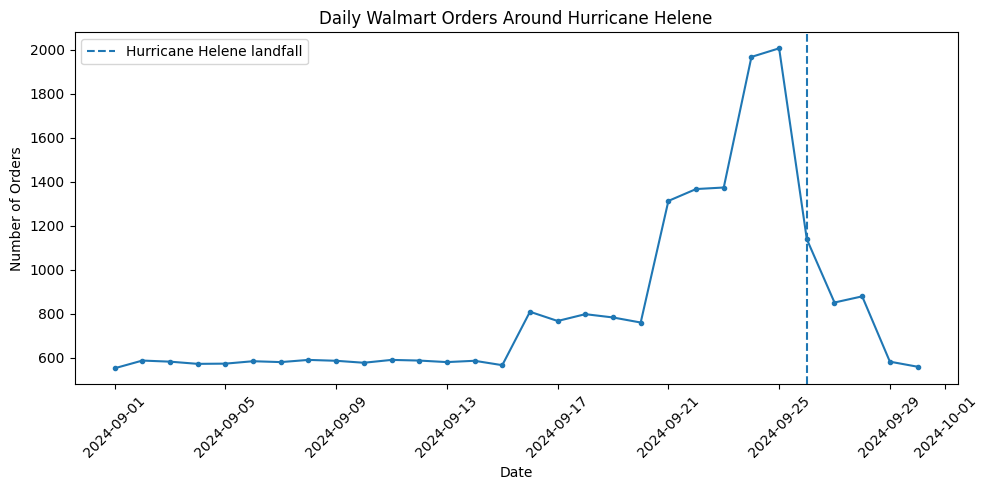

Days plotted: 30
Total transaction rows: 24648


In [14]:
# TODO

import matplotlib.pyplot as plt


daily_orders = (
    clean_tx.groupby("date")
    .size()
    .reset_index(name="orders")
    .sort_values("date")
)


plt.figure(figsize=(10, 5))

plt.plot(
    daily_orders["date"],
    daily_orders["orders"],
    marker="o",
    markersize=3
)


plt.axvline(
    pd.Timestamp("2024-09-26"),
    linestyle="--",
    label="Hurricane Helene landfall"
)

plt.title("Daily Walmart Orders Around Hurricane Helene")
plt.xlabel("Date")
plt.ylabel("Number of Orders")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Days plotted:", len(daily_orders))
print("Total transaction rows:", daily_orders["orders"].sum())


### 6 — Self-check

Fill in what you have and leave the rest. **The required items are the team setup and the charter.** Everything else is progress we want to see, not a pass or fail. The checks are shape checks; they cannot verify your analysis is right, only that you have gotten far enough to have one.

In [19]:
required = {
    'team_setup_complete': check_team(team_setup, quiet=True),   # from the team setup section
    'charter_committed': True,         # TODO: True once CHARTER.md shows in the git log above
}

progress = {
    'rows_after_cleaning': len(clean_tx),        # an integer
    'decisions_logged': len(decision_log),           # how many entries in your log
    'canonical_products': partial_groups,         # distinct products after consolidation
    'weather_api_rows': len(weather),           # rows returned by your API call
    'notebook_runs_clean': True,       # True after Restart and Run All
}

def is_done(value):
    return not (value is None or value is False
                or (isinstance(value, str) and value.startswith('TODO')))

def check(required, progress):
    print('REQUIRED')
    for label, value in required.items():
        print('  PASS' if is_done(value) else '  FAIL', '-', label, '=', value)
    print('PROGRESS (fill in what you have)')
    for label, value in progress.items():
        print('  done' if is_done(value) else '  not yet', '-', label, '=', value)
    ok = all(is_done(v) for v in required.values())
    print()
    print('required items complete:', ok)
    print('progress items done:', sum(is_done(v) for v in progress.values()), 'of', len(progress))
    return ok

check(required, progress)

REQUIRED
  PASS - team_setup_complete = True
  PASS - charter_committed = True
PROGRESS (fill in what you have)
  done - rows_after_cleaning = 24648
  done - decisions_logged = 5
  done - canonical_products = 42
  done - weather_api_rows = 30
  done - notebook_runs_clean = True

required items complete: True
progress items done: 5 of 5


True

### 7 — Risk and plan

Two questions, answered concretely.

**a)** What is the single most likely thing to go wrong in the next two weeks? Name a specific technical or team problem, not "running out of time."

**b)** What are you doing about it this week? Name who is doing it and by when.

**Biggest risk:** Our biggest risk is inconsistent product SKUs and store IDs, which could cause incorrect joins and misleading results. Although we have started cleaning the transaction data, we still need to validate our SKU mappings and confirm that the cleaned records match the other datasets.

**Plan, with an owner and a date:** Antony will validate the cleaning pipeline and expand the SKU mapping by October 27. Danny will test the weather API and check date alignment by October 28. We will review the results together before proceeding with the main analysis.

### 8 — Where each question stands

**TODO:** mark each of the five questions. These owners must match the question owners table in your charter. Be honest — this is the section I read first.

| Question | Status | Who owns it |
|---|---|---|
| Q1 demand surge | in progress | antony |
| Q2 SKU consolidation | in progress | antony |
| Q3 weather correlation | in progress | danny |
| Q4 store and geography | in progress | danny |
| Q5 signal or artifact | in progress | antony |

At the end of week 1, "not started" on Q4 and Q5 is expected. "Not started" on all five means come find me on Monday.